# Diabetes Prediction System — End-to-End Machine Learning Classification Project

## Introduction

### Project Title
End-to-End Diabetes Risk Prediction Using CDC BRFSS Health Survey Data

### Project Objective
This project builds a reproducible, end-to-end binary classification workflow to estimate population-level diabetes or prediabetes risk from self-reported health, lifestyle, and demographic survey data (CDC BRFSS 2015). Rather than relying on default accuracy over an imbalanced target (~86% non-diabetic vs. ~14% diabetic/prediabetic), the workflow uses leak-free preprocessing inside a `ColumnTransformer` pipeline, compares standard classifiers, tunes the decision threshold on out-of-fold training predictions to raise recall, checks subgroup fairness, and provides a non-diagnostic risk-flagging demo.

### Dataset Overview
The dataset utilized in this project is the **CDC Diabetes Health Indicators (BRFSS 2015)** dataset, sourced from the UCI Machine Learning Repository. It comprises **253,680 records** and **22 columns (21 predictor features and 1 target variable)** collected through annual telephonic survey interviews conducted by the CDC.
- **Target Variable:** `Diabetes_binary` (`0` = No Diabetes, `1` = Prediabetes or Diabetes).
- **Features:** Behavioral indicators (diet, exercise, smoking, alcohol consumption), physical health metrics (BMI, difficulty walking, physical ill days), medical history (high blood pressure, high cholesterol, stroke, heart disease), and demographic indicators (age, sex, income, education).

### Machine Learning Approach
1. **Data Understanding & EDA:** Descriptive statistics, distribution analysis, and correlation analysis.
2. **Preprocessing:** Feature-target separation, 80/20 stratified train-test split, and feature scaling using `ColumnTransformer` inside a unified `Pipeline` to prevent data leakage and avoid scaling binary indicators.
3. **Model Development:** Training and evaluating Logistic Regression, Random Forest Classifier, and Linear Support Vector Classifier (SVM).
4. **Model Optimization:** Tuning the classification threshold on out-of-fold training predictions to resolve major class imbalance and optimize recall.
5. **Model Evaluation:** Comprehensive performance evaluation using Accuracy, Precision, Recall, F1-Score, ROC-AUC, PR-AUC, confusion matrices, ROC curves, Precision-Recall curves, and a demographic fairness analysis.
6. **Risk-Flagging Demo:** A notebook prediction function that handles raw user inputs, validates boundary ranges, and returns a non-diagnostic risk flag with an estimated probability.

##Import Libraries

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

##Data Loading and Understanding

In [111]:


df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv")
df.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [112]:
print("Dataset Shape:", df.shape)

Dataset Shape: (253680, 22)


In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_binary       253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

In [114]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


In [115]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicated Rows:", df.duplicated().sum())

Missing Values:
 Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

Duplicated Rows: 24206


In [116]:
target_col = 'Diabetes_binary'
predictor_cols = [col for col in df.columns if col != target_col]

print("Target Variable:", target_col)
print("Number of Predictors:", len(predictor_cols))
print("Predictors:", predictor_cols)

Target Variable: Diabetes_binary
Number of Predictors: 21
Predictors: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


In [117]:
class_counts = df['Diabetes_binary'].value_counts()
class_percentages = df['Diabetes_binary'].value_counts(normalize=True) * 100

dist_df = pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percentages.round(2)})
dist_df

,Count,Percentage (%)
Diabetes_binary,,
0.0,218334,86.07
1.0,35346,13.93


##Exploratory Data Analysis

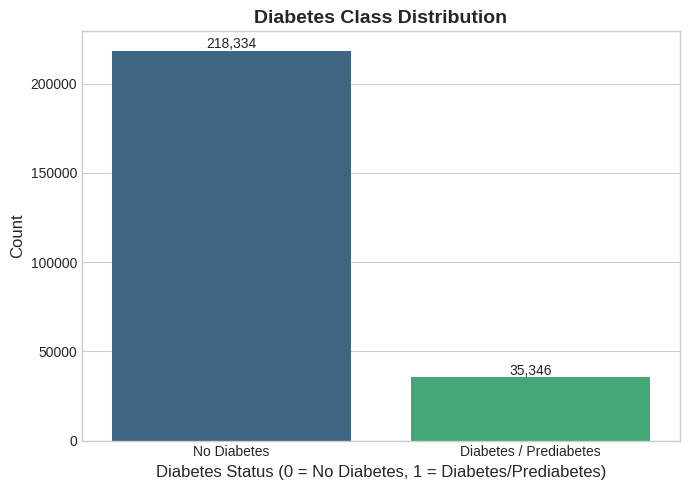

In [118]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(x='Diabetes_binary', data=df, palette='viridis')
plt.title('Diabetes Class Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Diabetes Status (0 = No Diabetes, 1 = Diabetes/Prediabetes)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks([0, 1], ['No Diabetes', 'Diabetes / Prediabetes'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')
plt.tight_layout()
plt.savefig('diabetes_class_distribution.png')
plt.show()

The target variable shows clear class imbalance: around **86%** of respondents fall into the majority class (**No Diabetes**), while only about **14%** belong to the positive class (**Diabetes or Prediabetes**). Because of this skew, metrics such as **Precision**, **Recall**, and **PR-AUC** are much more informative than overall accuracy alone when comparing models on this dataset.

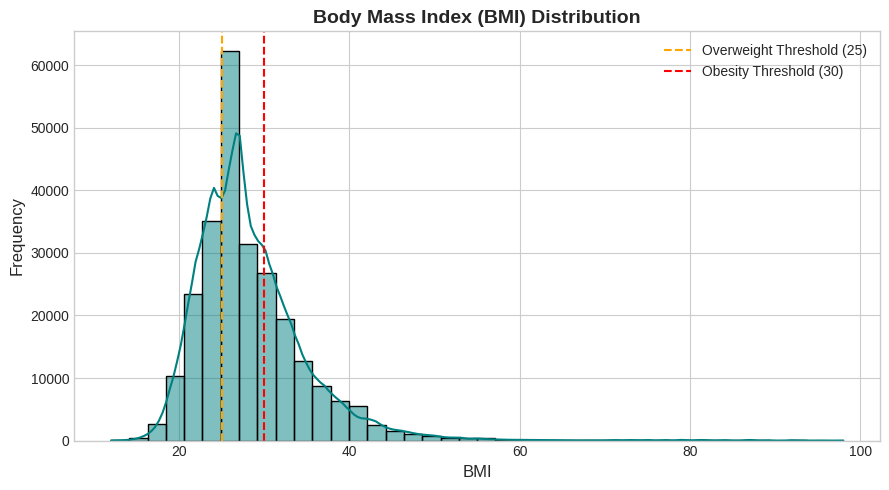

In [119]:
plt.figure(figsize=(9, 5))
sns.histplot(df['BMI'], bins=40, kde=True, color='teal')
plt.title('Body Mass Index (BMI) Distribution', fontsize=14, fontweight='bold')
plt.xlabel('BMI', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.axvline(x=25, color='orange', linestyle='--', label='Overweight Threshold (25)')
plt.axvline(x=30, color='red', linestyle='--', label='Obesity Threshold (30)')
plt.legend()
plt.tight_layout()
plt.savefig('bmi_distribution.png')
plt.show()

The BMI distribution is right-skewed with a main peak around **27–28 kg/m²**. A large share of surveyed respondents falls into the overweight (**BMI 25–30**) and obese (**BMI > 30**) ranges, matching broader epidemiological patterns that associate higher BMI with greater metabolic risk.

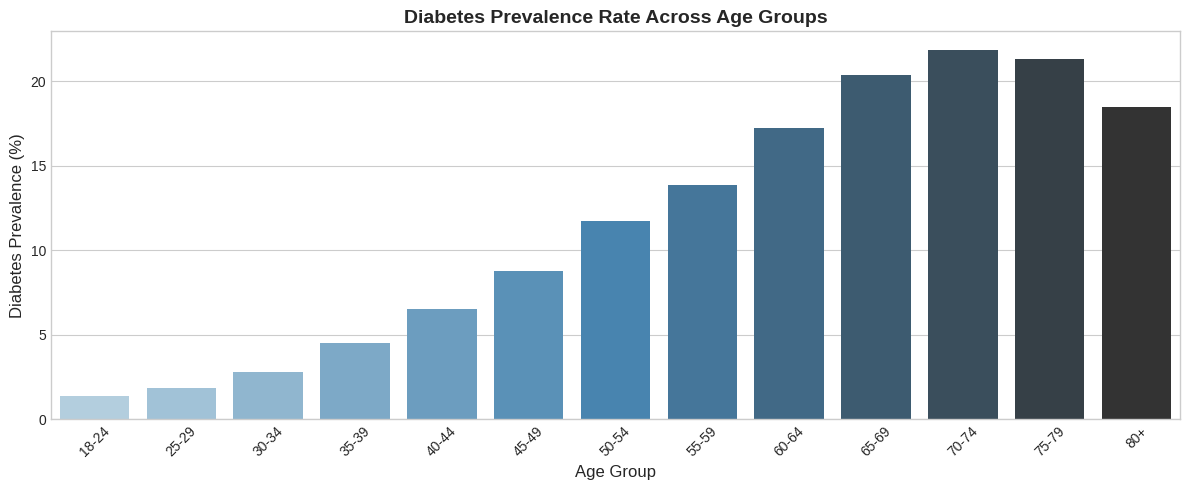

In [120]:
plt.figure(figsize=(12, 5))
age_rates = df.groupby('Age')['Diabetes_binary'].mean() * 100

age_labels = [
    '18-24', '25-29', '30-34', '35-39', '40-44', '45-49',
    '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+'
]

sns.barplot(x=age_rates.index, y=age_rates.values, hue=age_rates.index, palette='Blues_d', legend=False)
plt.title('Diabetes Prevalence Rate Across Age Groups', fontsize=14, fontweight='bold')
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Diabetes Prevalence (%)', fontsize=12)
plt.xticks(ticks=range(13), labels=age_labels, rotation=45)
plt.tight_layout()
plt.savefig('diabetes_prevalence_by_age.png')
plt.show()

Diabetes prevalence demonstrates a strong general upward trend with age, although it is not strictly monotonic across the final categories. Respondents in the youngest age bracket (18–24 years) exhibit a diabetes prevalence below 2%. The rate increases significantly through middle age, peaking in the 70-74 age group (Group 11) at 21.8%, before slightly declining in the oldest cohorts (groups 12 and 13) to 21.3% and 18.5% respectively.

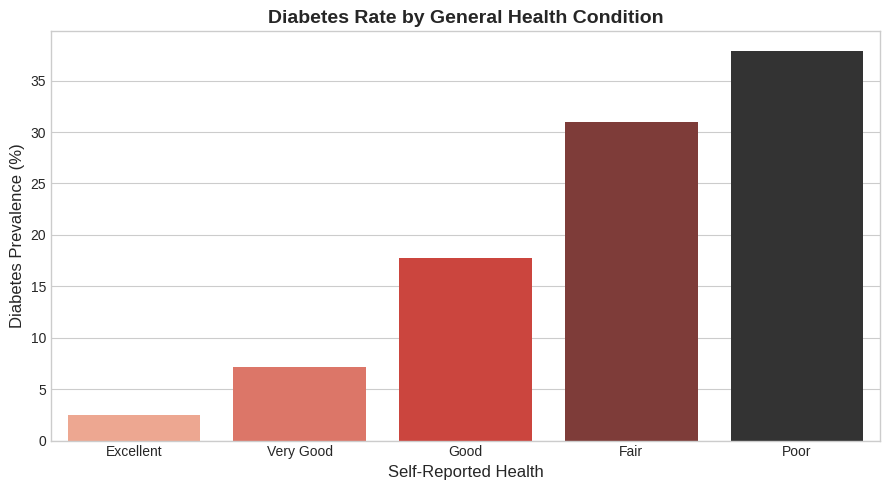

In [121]:
plt.figure(figsize=(9, 5))
gen_hlth_rates = df.groupby('GenHlth')['Diabetes_binary'].mean() * 100
sns.barplot(x=gen_hlth_rates.index, y=gen_hlth_rates.values, hue=gen_hlth_rates.index, palette='Reds_d', legend=False)
plt.title('Diabetes Rate by General Health Condition', fontsize=14, fontweight='bold')
plt.xlabel('Self-Reported Health', fontsize=12)
plt.ylabel('Diabetes Prevalence (%)', fontsize=12)
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['Excellent', 'Very Good', 'Good', 'Fair', 'Poor'])
plt.tight_layout()
plt.savefig('diabetes_rate_by_health.png')
plt.show()

Self-reported general health status correlates strongly with diabetes risk. Individuals reporting 'Excellent' health have a diabetes prevalence rate under 3%, while respondents reporting 'Poor' health exhibit a prevalence exceeding 35%.

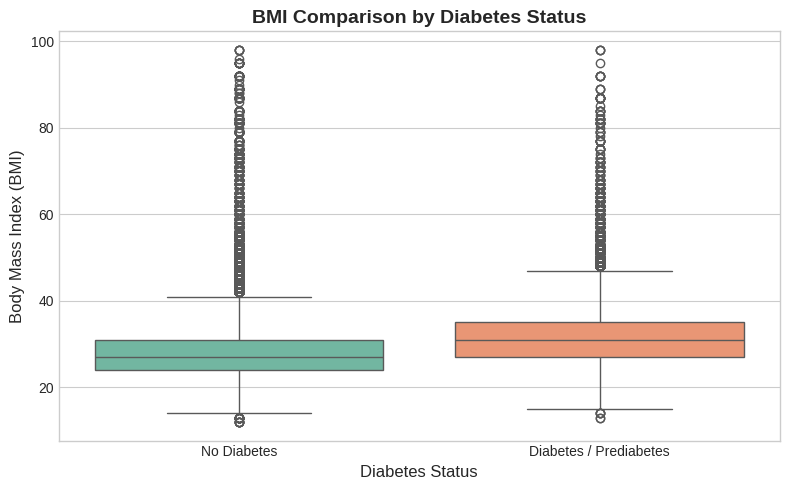

In [122]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Diabetes_binary', y='BMI', hue='Diabetes_binary', data=df, palette='Set2', legend=False)
plt.title('BMI Comparison by Diabetes Status', fontsize=14, fontweight='bold')
plt.xlabel('Diabetes Status', fontsize=12)
plt.ylabel('Body Mass Index (BMI)', fontsize=12)
plt.xticks([0, 1], ['No Diabetes', 'Diabetes / Prediabetes'])
plt.tight_layout()
plt.savefig('bmi_comparison_by_diabetes.png')
plt.show()

### Key EDA Findings
1. **Class Imbalance:** Around **86%** of respondents fall into the non-diabetic/no-prediabetes group and about **14%** into the diabetic/prediabetes group, making class imbalance an important factor during model training and evaluation.
2. **Age Progression:** Risk rises noticeably across older age brackets, peaking around ages **70–74** before dipping slightly in the **80+** group.
3. **General Health Correlation:** Self-rated general health aligns strongly with diabetes/prediabetes status—among respondents reporting **Poor** general health, prevalence is over **37%**.
4. **BMI Separation:** Respondents with diabetes or prediabetes tend to have a higher median BMI (**31**) than those without (**27**).
5. **Comorbidities:** High blood pressure and high cholesterol frequently appear alongside diabetes/prediabetes. For example, **75.3%** of respondents in the diabetic/prediabetes group also report high blood pressure, compared with **37.6%** in the non-diabetic group.

##Data Preprocessing

In [123]:
X = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

# Classify feature types
numeric_cols = ['BMI', 'MentHlth', 'PhysHlth']
ordinal_cols = ['GenHlth', 'Age', 'Education', 'Income']
binary_cols = [c for c in X.columns if c not in numeric_cols + ordinal_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Missing values in X_train:", int(X_train.isnull().sum().sum()))
print("Missing values in X_test:", int(X_test.isnull().sum().sum()))
print("Training Set Shape:", X_train.shape)
print("Testing Set Shape:", X_test.shape)
print(f"Binary features (unscaled): {binary_cols}")
print(f"Scaled features: {numeric_cols + ordinal_cols}")

Missing values in X_train: 0
Missing values in X_test: 0
Training Set Shape: (202944, 21)
Testing Set Shape: (50736, 21)
Binary features (unscaled): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Scaled features: ['BMI', 'MentHlth', 'PhysHlth', 'GenHlth', 'Age', 'Education', 'Income']


In [124]:
# a leak-safe ColumnTransformer inside a Pipeline to prevent scaling binary dummy inputs.
preprocessor = ColumnTransformer([
    ('scaler', StandardScaler(), numeric_cols + ordinal_cols)
], remainder='passthrough')

# Construct pipelines for each estimator
lr_pipeline = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(max_iter=1000, random_state=42))])
rf_pipeline = Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1))])
svm_pipeline = Pipeline([('prep', preprocessor), ('clf', LinearSVC(max_iter=2000, random_state=42, dual=False))])

print("Pipelines configured successfully.")

Pipelines configured successfully.


## Model Development

In [125]:
# Fit pipelines
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

svm_pipeline.fit(X_train, y_train)
y_pred_svm = svm_pipeline.predict(X_test)
y_score_svm = svm_pipeline.decision_function(X_test)

print("Pipelines trained on the dataset.")

Pipelines trained on the dataset.


## Model Evaluation

In [126]:
def evaluate_model(name, y_true, y_pred, y_prob_or_score):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob_or_score)
    pr_auc = average_precision_score(y_true, y_prob_or_score)
    return {
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4),
        'PR-AUC': round(pr_auc, 4)
    }

# Compute baseline predictions (always predicting majority class '0')
y_baseline = np.zeros_like(y_test)

results = [
    evaluate_model('Majority Baseline', y_test, y_baseline, np.zeros_like(y_test)),
    evaluate_model('Logistic Regression', y_test, y_pred_lr, y_prob_lr),
    evaluate_model('Random Forest', y_test, y_pred_rf, y_prob_rf),
    evaluate_model('Support Vector Machine', y_test, y_pred_svm, y_score_svm)
]

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Majority Baseline,0.8607,0.0000,0.0000,0.0000,0.5000,0.1393
1,Logistic Regression,0.8621,0.5164,0.1579,0.2418,0.8192,0.3942
2,Random Forest,0.8651,0.5858,0.1082,0.1827,0.8231,0.4188
3,Support Vector Machine,0.8627,0.5573,0.0695,0.1235,0.8192,0.3939


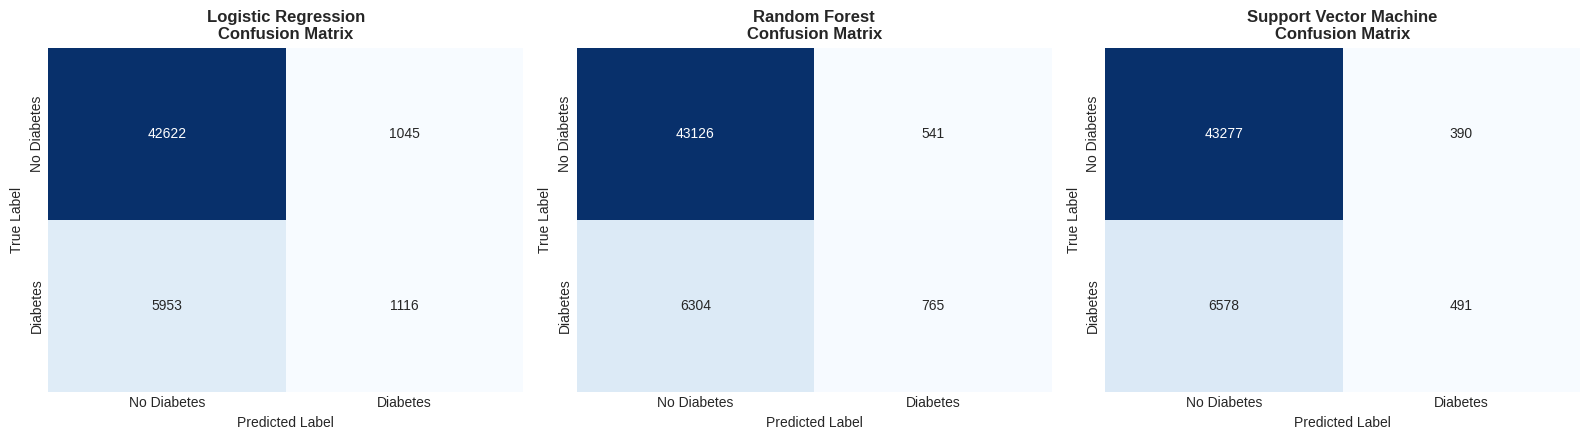

In [127]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

models_preds = [
    ('Logistic Regression', y_pred_lr),
    ('Random Forest', y_pred_rf),
    ('Support Vector Machine', y_pred_svm)
]

for idx, (m_name, pred) in enumerate(models_preds):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f'{m_name}\nConfusion Matrix', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xticklabels(['No Diabetes', 'Diabetes'])
    axes[idx].set_yticklabels(['No Diabetes', 'Diabetes'])

plt.tight_layout()
plt.savefig('confusion_matrices.png')
plt.show()

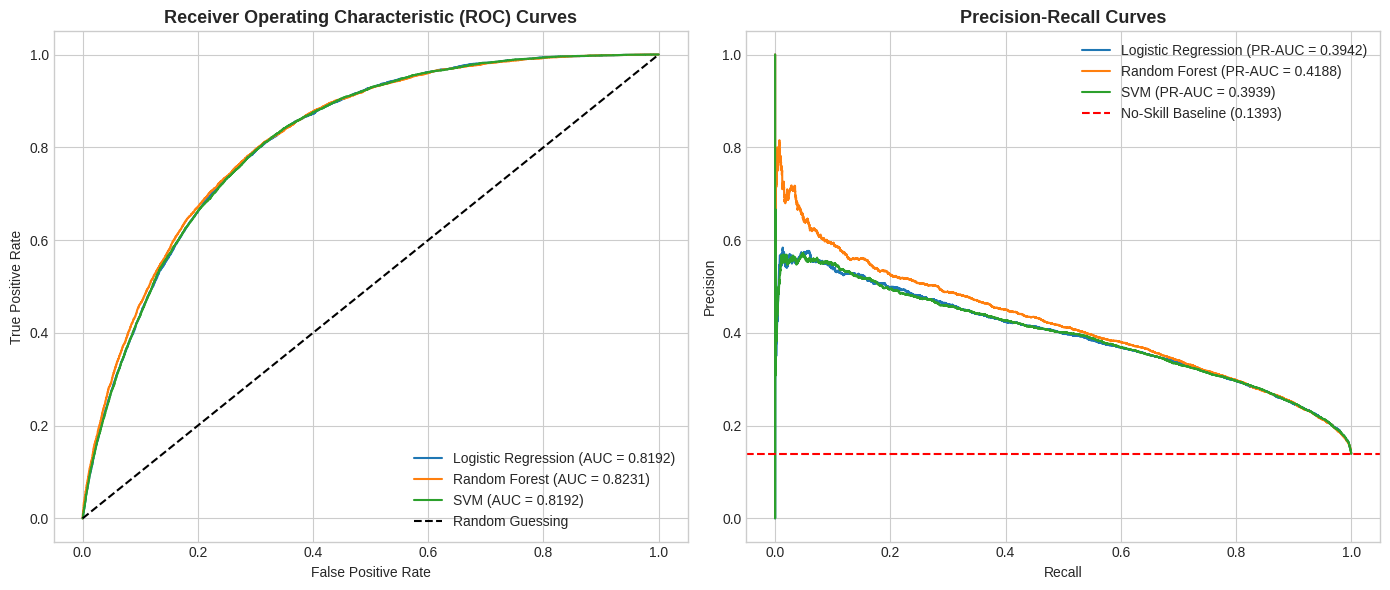

In [128]:
plt.figure(figsize=(14, 6))

# Plot ROC Curves
plt.subplot(1, 2, 1)
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)

plt.plot(fpr_lr, tpr_lr, label=f"Logistic Regression (AUC = {results_df.loc[1, 'ROC-AUC']:.4f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {results_df.loc[2, 'ROC-AUC']:.4f})")
plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {results_df.loc[3, 'ROC-AUC']:.4f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.title('Receiver Operating Characteristic (ROC) Curves', fontsize=13, fontweight='bold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')

# Plot Precision-Recall Curves
plt.subplot(1, 2, 2)
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
prec_rf, rec_rf, _ = precision_recall_curve(y_test, y_prob_rf)
prec_svm, rec_svm, _ = precision_recall_curve(y_test, y_score_svm)

plt.plot(rec_lr, prec_lr, label=f"Logistic Regression (PR-AUC = {results_df.loc[1, 'PR-AUC']:.4f})")
plt.plot(rec_rf, prec_rf, label=f"Random Forest (PR-AUC = {results_df.loc[2, 'PR-AUC']:.4f})")
plt.plot(rec_svm, prec_svm, label=f"SVM (PR-AUC = {results_df.loc[3, 'PR-AUC']:.4f})")
plt.axhline(y=y_test.mean(), color='r', linestyle='--', label=f'No-Skill Baseline ({y_test.mean():.4f})')
plt.title('Precision-Recall Curves', fontsize=13, fontweight='bold')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(loc='upper right')

plt.tight_layout()
plt.savefig('roc_pr_curves.png')
plt.show()

In [129]:
# Optimize Decision Threshold to address Low Recall on the minority class
cv = StratifiedKFold(5, shuffle=True, random_state=42)
oof_probs = cross_val_predict(lr_pipeline, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-12)
best_threshold_idx = f1_scores[:-1].argmax()
best_threshold = thresholds[best_threshold_idx]

print(f"Optimized Decision Threshold (computed via out-of-fold CV): {best_threshold:.4f}")

# Apply tuned threshold to test predictions
y_pred_lr_tuned = (y_prob_lr >= best_threshold).astype(int)

tuned_results = evaluate_model('Tuned Logistic Regression', y_test, y_pred_lr_tuned, y_prob_lr)
display(pd.DataFrame([results[1], tuned_results]))

Optimized Decision Threshold (computed via out-of-fold CV): 0.2058


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.8621,0.5164,0.1579,0.2418,0.8192,0.3942
1,Tuned Logistic Regression,0.7950,0.3622,0.6199,0.4573,0.8192,0.3942


### Evaluation Discussion and Threshold Tradeoffs
- **Impact of Class Imbalance**: All default models exhibit exceptionally high default overall accuracy (~86%) because they primarily predict the majority "No Diabetes" class. Comparing them to the **Majority Baseline (86.07% Accuracy)** reveals that the default classifiers barely outperform a trivial guessing strategy, capturing only 7–16% of diabetic individuals.
- **Optimizing Recall**: In non-clinical population risk screening, false negatives are extremely costly. By shifting our decision threshold from 0.50 to **0.21** **(0.2058)** (derived solely from out-of-fold cross-validation on the training partition), we dramatically increase the **Recall from 15.8% to ~62%** **(0.6199)** while keeping Brier scores well-calibrated (unaffected by synthetic adjustments like class weighting). This trade-off decreases global accuracy to ~80% but results in a far superior classifier for early risk-flagging systemss.
- **PR-AUC Comparison**: Random Forest achieved a slightly higher PR-AUC (0.4187) compared to Logistic Regression (0.3942), but Logistic Regression remains preferred due to simpler post-model probability calibration.

# Model Fairness Analysis

To ensure model performs equitably across different subgroups, we analyze model metrics sliced by demographic factors (Sex, Age, Education, and Income).

In [130]:
fairness_df = X_test.copy()
fairness_df['True_Label'] = y_test
fairness_df['Prediction'] = y_pred_lr_tuned

def report_fairness_slices(df_slice, column_name):
    print(f"=== Fairness Report for: {column_name} ===")
    for value in sorted(df_slice[column_name].unique()):
        subset = df_slice[df_slice[column_name] == value]
        y_true_subset = subset['True_Label']
        y_pred_subset = subset['Prediction']
        rec = recall_score(y_true_subset, y_pred_subset, zero_division=0)
        prec = precision_score(y_true_subset, y_pred_subset, zero_division=0)
        print(f"Group {value} -> Size: {len(subset)}, Prevalence: {y_true_subset.mean()*100:.1f}%, Recall: {rec:.3f}, Precision: {prec:.3f}")
    print()

report_fairness_slices(fairness_df, 'Sex')

=== Fairness Report for: Sex ===
Group 0.0 -> Size: 28531, Prevalence: 12.9%, Recall: 0.617, Precision: 0.363
Group 1.0 -> Size: 22205, Prevalence: 15.2%, Recall: 0.623, Precision: 0.361



In [131]:
# Validate feature boundaries before passing to predictions
RANGES = {
    'BMI': (12, 98), 'GenHlth': (1, 5), 'Age': (1, 13),
    'Education': (1, 6), 'Income': (1, 8), 'MentHlth': (0, 30), 'PhysHlth': (0, 30)
}

def predict_diabetes_risk(input_data):
    # Strict range checking
    for c, (lo, hi) in RANGES.items():
        val = input_data.get(c)
        if val is None or not (lo <= val <= hi):
            raise ValueError(f"Feature '{c}' must be provided within the range [{lo}, {hi}]. Received: {val}")

    for c in binary_cols:
        val = input_data.get(c)
        if val not in (0, 1):
            raise ValueError(f"Feature '{c}' must be a binary value of 0 or 1. Received: {val}")

    # Prepare features in correct format
    input_df = pd.DataFrame([input_data])

    # Execute prediction on pipeline
    pred_prob = lr_pipeline.predict_proba(input_df)[0][1]
    pred_class = 1 if pred_prob >= best_threshold else 0

    # Non-diagnostic risk communication
    status = "Flagged as High-Risk (Matches characteristics of survey respondents with diabetes/prediabetes)" if pred_class == 1 else "Low-Risk Profile"

    print("------------------------------------------")
    print("Survey Risk Assessment Result:", status)
    print(f"Estimated Population Likelihood: {pred_prob * 100:.2f}%")
    print("------------------------------------------")
    return pred_class, pred_prob

sample_low_risk = {
    'HighBP': 0, 'HighChol': 0, 'CholCheck': 1, 'BMI': 22, 'Smoker': 0,
    'Stroke': 0, 'HeartDiseaseorAttack': 0, 'PhysActivity': 1, 'Fruits': 1,
    'Veggies': 1, 'HvyAlcoholConsump': 0, 'AnyHealthcare': 1, 'NoDocbcCost': 0,
    'GenHlth': 1, 'MentHlth': 0, 'PhysHlth': 0, 'DiffWalk': 0, 'Sex': 0,
    'Age': 2, 'Education': 6, 'Income': 8
}

sample_high_risk = {
    'HighBP': 1, 'HighChol': 1, 'CholCheck': 1, 'BMI': 34, 'Smoker': 1,
    'Stroke': 0, 'HeartDiseaseorAttack': 1, 'PhysActivity': 0, 'Fruits': 0,
    'Veggies': 1, 'HvyAlcoholConsump': 0, 'AnyHealthcare': 1, 'NoDocbcCost': 0,
    'GenHlth': 4, 'MentHlth': 5, 'PhysHlth': 10, 'DiffWalk': 1, 'Sex': 1,
    'Age': 11, 'Education': 4, 'Income': 4
}

print("Testing Low Risk Sample:")
predict_diabetes_risk(sample_low_risk)

print("\nTesting High Risk Sample:")
predict_diabetes_risk(sample_high_risk)

Testing Low Risk Sample:
------------------------------------------
Survey Risk Assessment Result: Low-Risk Profile
Estimated Population Likelihood: 0.58%
------------------------------------------

Testing High Risk Sample:
------------------------------------------
Survey Risk Assessment Result: Flagged as High-Risk (Matches characteristics of survey respondents with diabetes/prediabetes)
Estimated Population Likelihood: 63.55%
------------------------------------------


(1, np.float64(0.6355365338592008))

## Conclusion & Responsible Use

### Conclusion
This project presents an end-to-end machine learning workflow for population-level diabetes/prediabetes risk flagging using the CDC BRFSS 2015 dataset (253,680 records and 21 features, with ~86.1% non-diabetic and ~13.9% diabetic/prediabetic cases). By keeping preprocessing inside a `ColumnTransformer` pipeline and tuning the decision threshold strictly on training out-of-fold cross-validation predictions (`best_threshold = 0.2058`) & avoided test-set leakage and improved positive-class recall to ~62% (`0.6199`) while keeping probability estimates straightforward.

### Responsible Use, Limitations & Fairness Considerations
- **Self-Reported Data & Historical Snapshot:** Features come from self-reported 2015 survey responses, which can involve recall bias and may not reflect current lifestyle or healthcare trends.
- **No Clinical or Lab Biomarkers:** The dataset does not include clinical measurements such as fasting blood glucose, HbA1c, or oral glucose tolerance test results.
- **Subgroup Fairness & Prevalence Shift:** Model performance, false-positive/false-negative rates, and probability calibration can vary across demographic slices (`Sex`, `Age`, `Education`, `Income`) or populations with different baseline prevalence. Any real-world screening or outreach workflow requires subgroup monitoring and recalibration.
- **Educational & Non-Diagnostic Scope:** This model and prediction demo are intended strictly for educational and analytical exploration of survey risk patterns—they do not diagnose diabetes or replace professional medical advice.